# 01 · APIs and your first machine learning model


Maya runs a support desk. For her shift handover, she wants a short summary of tickets already open. For a new customer, she wants an estimate of how many minutes it will take for someone to pick up the ticket. In this notebook you will calculate facts with Python, ask a language model to write a summary, and train a separate model that predicts waiting time.

You should already know Python lists, dictionaries, functions and basic pandas. Work through the notebook from top to bottom and try each check before reading the answer.

1. Set up Python.
2. Send HTTP requests, try Ollama and Groq, and handle failures.
3. Train and use a first linear regression model.
4. Build a ticket report that can still save facts if the language model fails.
5. Evaluate classical ML models for classification and regression.

## 1. Set up your notebook

Use a Python 3.10 or newer kernel. If imports fail, run the following command in a separate notebook cell, then restart the kernel. The percent sign tells Jupyter to install packages into the active kernel environment.

```python
%pip install requests python-dotenv numpy pandas matplotlib scikit-learn
```

Open this notebook from the course checkout. The first run can use Jupyter's **Restart Kernel and Run All Cells** with the default settings. The API cells use example responses, the reporting exercise saves the offline fallback, and the ML cells train and score real scikit-learn models on synthetic data.

## 2. Send a request and read JSON

An API gives Python a way to ask another program for data or an action. An HTTP request has a URL and a method. `GET` typically retrieves data. Here, `POST` sends input for a model to process. Headers carry request metadata such as credentials. The body of our `POST` holds the model name and messages.

The server responds with a status code and a body. A status of `200` means the server reports success. With a JSON object in the body, `response.json()` gives us a Python dictionary. We'll keep the status and a field from the body side by side.

**Try first.** How would you read the value stored under the key `completed`?

In [1]:
import json
import os
from pathlib import Path

import requests
from IPython.display import display

# Change to True to send a real GET request when you run this cell.
RUN_LIVE_HTTP = False

if RUN_LIVE_HTTP:
    # Give the server a timeout so a slow response can raise an error.
    response = requests.get(
        "https://jsonplaceholder.typicode.com/todos/1",
        timeout=10,
    )
    response.raise_for_status()
    status_code = response.status_code
    task = response.json()  # Decode the JSON object into a dictionary.
    print("Source: live GET")
else:
    status_code = 200
    task = {"id": 1, "title": "Review the morning tickets", "completed": False}
    print("Source: example GET response")

print("HTTP status:", status_code)
print(task)
print("Completed:", task["completed"])

Source: example GET response
HTTP status: 200
{'id': 1, 'title': 'Review the morning tickets', 'completed': False}
Completed: False


**Answer.** Use `task["completed"]`. The status says whether the request succeeded. The `completed` value describes the task itself. In the example the status is `200` and the task has `completed = False`.

### Ask a language model to summarize known facts

Suppose a pandas calculation gave us the three counts below. `json.dumps()` turns the dictionary into JSON text so we can include it in the message. A request to a trained model to produce an answer is called **inference**.

**Try first.** If the message just said “summarize today's tickets,” what information would the model need from us?

In [2]:
# These are the facts from last week's support-ticket exercise.
ticket_facts = {
    "open_tickets": 5,
    "open_tickets_waiting_at_least_30_minutes": 3,
    "open_tickets_with_unknown_wait": 1,
}

prompt = (
    "Write a two-sentence update for the support lead. "
    "Use only these ticket facts and keep the numbers as given.\n"
    + json.dumps(ticket_facts)
)
# Inspect the message and confirm that all three counts are present.
print(prompt)

Write a two-sentence update for the support lead. Use only these ticket facts and keep the numbers as given.
{"open_tickets": 5, "open_tickets_waiting_at_least_30_minutes": 3, "open_tickets_with_unknown_wait": 1}


**Answer.** The model needs the ticket facts. Read the returned wording against the counts, including whether it keeps “at least 30.”

### Call Ollama locally

Both calls put a role and message in a list of messages. For Ollama, `stream=False` requests a single response and `think=False` requests no thinking output. Groq uses the hosted chat completions endpoint and a bearer token in the request header. We use the same POST helper for both providers. [Ollama chat API](https://docs.ollama.com/api/chat) · [Groq chat API](https://console.groq.com/docs/api-reference#chat-create).

#### Optional Ollama setup

Install and start Ollama on the same computer as the Python kernel. In a terminal, run `ollama pull qwen3.5:4b` to download the example model. If the Ollama service is stopped, open the Ollama app or start it with `ollama serve`. Set `RUN_LIVE_OLLAMA = True` in the demo cell below and run that cell. The address `127.0.0.1` points to the machine running the kernel, so a hosted notebook should use the offline example unless Ollama is running on that host. [Ollama chat API](https://docs.ollama.com/api/chat) · [Qwen model page](https://ollama.com/library/qwen3.5%3A4b).

In [3]:
# Set to True after starting Ollama and pulling the model.
RUN_LIVE_OLLAMA = False


def post_json(url: str, payload: dict, timeout: int, headers: dict | None = None) -> dict:
    # json= serializes the Python dictionary and marks the request body as JSON.
    response = requests.post(url, json=payload, headers=headers, timeout=timeout)
    response.raise_for_status()  # Turn an HTTP failure into a Python exception.
    return response.json()


def ask_ollama(prompt_text: str) -> dict:
    payload = {
        "model": "qwen3.5:4b",
        "messages": [{"role": "user", "content": prompt_text}],
        "stream": False,
        "think": False,
    }
    return post_json("http://127.0.0.1:11434/api/chat", payload, timeout=90)


if RUN_LIVE_OLLAMA:
    ollama_reply = ask_ollama(prompt)
    print("Source: live Ollama")
else:
    # The sample has the same nested fields we read from a live reply.
    ollama_reply = {
        "message": {
            "role": "assistant",
            "content": (
                "Five tickets are open, and three have waited at least 30 minutes. "
                "One open ticket has an unknown wait."
            ),
        }
    }
    print("Source: example Ollama response")

print(ollama_reply["message"]["content"])

Source: example Ollama response
Five tickets are open, and three have waited at least 30 minutes. One open ticket has an unknown wait.


### Call Groq from Python

Ollama puts the answer under `message → content`. Groq puts it under `choices → first item → message → content`. The list index `[0]` selects the first choice. Read those steps from left to right when you debug a nested response.

#### Optional Groq setup · Create a private `.env` file

A `.env` file is a plain-text file with one setting per line. We use it to keep the API key in local configuration. The example response works with the default setting in the Groq demo.

1. Sign in and create a key in the [Groq API Keys console](https://console.groq.com/keys).
2. Open the course repository in VS Code. In `04-machine-learning-foundations/`, create or open a file named exactly **`.env`** beside this notebook. On macOS or Linux, you can also open a terminal in that folder and run `nano .env`. On Windows PowerShell, use `notepad .env` and check the filename if Notepad adds `.txt`.
3. Add the following line to that file. Replace the example value with your own key and save.

```dotenv
GROQ_API_KEY=replace_with_your_own_key
```

4. The repository's `.gitignore` already ignores `.env`. From the repository root, `git check-ignore 04-machine-learning-foundations/.env` should print the ignored path. Keep your real key out of notebook cells, printed output, screenshots and commits.
5. Start the kernel from the module folder or from the repository root. The helper below checks the module folder and then looks up the directory tree for an existing course `.env`. To see where Python starts looking, run `Path.cwd()` in a Python cell after running the HTTP demo.
6. Set `RUN_LIVE_GROQ = True` in the demo cell below and run that cell. The helper loads settings with `python-dotenv` and reads `GROQ_API_KEY` with `os.getenv()`. A key already set in the environment takes precedence. If you edit the file after a key was loaded, restart the kernel and rerun the cells.

If you see a missing-key message, check the working folder, exact filename and variable name. A `401` usually points to a missing or invalid credential. Set `RUN_LIVE_GROQ` back to `False` to continue with the example response. [python-dotenv documentation](https://pypi.org/project/python-dotenv/).

In [4]:
# Set to True after saving your Groq key in .env.
RUN_LIVE_GROQ = False


def get_groq_key() -> str:
    from dotenv import find_dotenv, load_dotenv

    module_env = Path("04-machine-learning-foundations") / ".env"
    # Support launching Jupyter from the course root or from the module folder.
    env_path = module_env if module_env.is_file() else find_dotenv(usecwd=True)
    if env_path:
        load_dotenv(env_path, override=False)

    api_key = os.getenv("GROQ_API_KEY", "").strip()
    if not api_key or api_key == "replace_with_your_own_key":
        raise RuntimeError("Set GROQ_API_KEY in your private .env before the live call.")
    return api_key


def ask_groq(prompt_text: str) -> dict:
    payload = {
        "model": "openai/gpt-oss-20b",
        "messages": [{"role": "user", "content": prompt_text}],
    }
    headers = {"Authorization": f"Bearer {get_groq_key()}"}
    return post_json(
        "https://api.groq.com/openai/v1/chat/completions",
        payload,
        timeout=30,
        headers=headers,
    )


if RUN_LIVE_GROQ:
    groq_reply = ask_groq(prompt)
    print("Source: live Groq")
else:
    groq_reply = {
        "choices": [
            {
                "message": {
                    "role": "assistant",
                    "content": (
                        "Of the five open tickets, three have been waiting at least 30 minutes. "
                        "One open ticket has no recorded wait."
                    ),
                }
            }
        ]
    }
    print("Source: example Groq response")

# Follow four lookups to reach the string we want.
print(groq_reply["choices"][0]["message"]["content"])

Source: example Groq response
Of the five open tickets, three have been waiting at least 30 minutes. One open ticket has no recorded wait.


### Read nested fields and handle failures

Use `message["content"]` for required text so a missing key is visible. Use `message.get("note", "No note was sent")` for optional fields with a default. A field that exists with JSON `null` becomes Python `None`, so the default is only used if the key is absent.

In [5]:
# Break the lookup into steps to see the type at each level.
choices = groq_reply["choices"]
first_choice = choices[0]
message = first_choice["message"]

print("choices:", type(choices).__name__)
print("first_choice:", type(first_choice).__name__)
print("Required text:", message["content"])
print("Optional note:", message.get("note", "No note was sent"))

choices: list
first_choice: dict
Required text: Of the five open tickets, three have been waiting at least 30 minutes. One open ticket has no recorded wait.
Optional note: No note was sent


A failure can happen before we receive a response (a timeout), in the HTTP status (`401` for an authentication problem, `404` for a missing URL, `429` for a rate limit), or when we parse and read the response (invalid JSON or missing fields). Even text from a successful request needs a factual check. These two examples simulate error cases locally.

In [6]:
# This example has a choice and a message, but its message has no content.
incomplete_reply = {"choices": [{"message": {"role": "assistant"}}]}

try:
    summary = incomplete_reply["choices"][0]["message"]["content"]
except KeyError as error:
    print("Cannot build the report. Missing field:", error)

Cannot build the report. Missing field: 'content'


In [7]:
# Create a response object locally to practice without making a request.
denied_response = requests.Response()
denied_response.status_code = 401
denied_response.reason = "Unauthorized"

try:
    denied_response.raise_for_status()
except requests.HTTPError as error:
    print("Could not fetch a summary:", error.response.status_code)

Could not fetch a summary: 401


**Check.** Why does the first example raise `KeyError`? The required `content` key is missing. If `choices` were an empty list, `[0]` would instead raise `IndexError`. In the second cell, `raise_for_status()` turns the simulated `401` into `HTTPError`.

### Return the summary as a value

Write a small function that returns the text. The calling code can put that value in a report, and the original facts stay available to check the wording.

In [8]:
def read_groq_text(reply: dict) -> str:
    # Move from the list of choices to the first message dictionary.
    return reply["choices"][0]["message"]["content"]


report = {
    "facts": ticket_facts,
    "summary": read_groq_text(groq_reply),
}
print(json.dumps(report, indent=2))

{
  "facts": {
    "open_tickets": 5,
    "open_tickets_waiting_at_least_30_minutes": 3,
    "open_tickets_with_unknown_wait": 1
  },
  "summary": "Of the five open tickets, three have been waiting at least 30 minutes. One open ticket has no recorded wait."
}


## 3. Train a model to estimate waiting time

A customer is about to open a ticket. The queue tool sees 12 tickets ahead. Past tickets tell us how long people actually waited under different conditions. We can learn a relationship from that history and give the assistant a Python function to call for an estimate.

| Type of learning | What the model learns from | Support example |
| --- | --- | --- |
| Supervised | Examples with recorded answers | Predict wait minutes from queue size. |
| Unsupervised | Examples without an answer column for the task | Group tickets with similar descriptions. |
| Reinforcement learning | Rewards collected after taking actions | Learn a routing policy in a simulated helpdesk. |

This chapter uses **supervised learning**. **Regression** predicts a numerical value such as wait minutes. **Binary classification** predicts one of two labels, such as whether a wait will be over 30 minutes. **Multiclass classification** predicts one of several labels, such as billing, login or delivery.

### Start with a hand-written rule

A **baseline** is a simple approach we use as a point of comparison. Start at four minutes and add two minutes for each ticket ahead. Predict the result with six tickets in the queue before running this cell.

In [9]:
def rule_wait_minutes(queue_size: int) -> int:
    # These two numbers are chosen by hand.
    return 4 + 2 * queue_size


print("Estimated wait:", rule_wait_minutes(6), "minutes")

Estimated wait: 16 minutes


**Answer.** `4 + 2 × 6 = 16` minutes. A fitted model will learn its own intercept and slope from examples.

### Read a historical row

A **sample** is one ticket. A **feature** is information we can use at arrival, such as `queue_size` or `agents_on_duty`. The **target** is the answer we want to predict, here `wait_minutes`, recorded when the ticket is picked up.

Ticket category is a **categorical** feature, while the queue size is **numerical**. Categorical inputs need appropriate encoding before they can go into a model such as linear regression. A zero recorded wait means immediate pickup. A blank wait means the target is unknown, so that row needs handling before supervised training.

The next cell generates 120 **synthetic** tickets. We seed the random generator so both student notebooks can reproduce the same history. A small random variation allows two similar tickets to have different waits.

In [10]:
import numpy as np
import pandas as pd

# Use a fixed seed so rerunning this cell creates the same 120 example rows.
rng = np.random.default_rng(42)

# Each row gets a queue size from 0 to 24 and a staff count from 2 to 6.
# rng.integers() excludes the upper limit.
queue_size = rng.integers(0, 25, size=120)
agents_on_duty = rng.integers(2, 7, size=120)

# Add a random change to each wait. It is centered at 0 with a standard deviation of 4 minutes.
# The standard deviation describes the scale of the random variation.
variation = rng.normal(0, 4, size=120)

# Simulate waits. Start at 14 minutes, add 1.6 per ticket ahead, and subtract 2.6 per agent.
# The random change lets tickets with the same queue and staff counts have different waits.
wait_minutes = 14 + 1.6 * queue_size - 2.6 * agents_on_duty + variation

# Floor the synthetic waits at one minute and round the stored target.
ticket_history = pd.DataFrame({
    "queue_size": queue_size,
    "agents_on_duty": agents_on_duty,
    "wait_minutes": np.maximum(wait_minutes, 1).round(1),
})
display(ticket_history.head())

,queue_size,agents_on_duty,wait_minutes
0,2,4,13.2
1,19,5,30.4
2,16,5,22.5
3,10,4,20.3
4,10,6,15.3


**Check.** Could the model use the time the ticket was picked up? That time is only known later and reveals part of the answer. Using it for a prediction made at arrival would be **data leakage**.

### Prepare the feature table and target series

`X` is a DataFrame, with one row per ticket and one column per feature. `y` is a Series, with one recorded answer per ticket. A list of column names inside brackets preserves the shape of the input table.

In [11]:
# The inner brackets make a list of feature names.
X = ticket_history[["queue_size"]]
y = ticket_history["wait_minutes"]

print("X:", type(X).__name__, X.shape)
print("y:", type(y).__name__, y.shape)

X: DataFrame (120, 1)
y: Series (120,)


The shapes are `X = (120, 1)` and `y = (120,)`. During training the feature rows and recorded answers must stay paired, so pass them together when splitting.

| Split | Rows | Purpose |
| --- | ---: | --- |
| Training | 72 | Learn the model parameters. |
| Validation | 24 | Compare approaches or tune an alert cutoff using a metric chosen for the task. |
| Test | 24 | Check the selected approach once, after the choices are made. |

The first split sets aside 20% for testing. The second takes 25% of the remaining 96 rows for validation. Random splitting fits this example because the generated rows have no time order. With real ticket arrivals, an older-to-newer split can better represent how the model will be used.

In [12]:
from sklearn.model_selection import train_test_split

# Hold back test rows first. X and y are split in matching order.
X_pool, X_test, y_pool, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# Split the remaining rows into training and validation.
X_train, X_val, y_train, y_val = train_test_split(
    X_pool, y_pool, test_size=0.25, random_state=42
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

Training rows: 72
Validation rows: 24
Test rows: 24


### Visualize the training data, then fit a line

Each dot represents a training ticket. An upward pattern would give us a reason to try a line. Spread at the same queue size tells us a queue-only model will give an approximation.

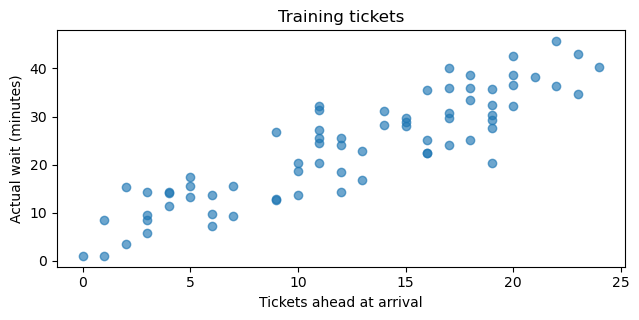

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6.5, 3.3))
# Draw only the training rows during this first exploration.
plt.scatter(X_train["queue_size"], y_train, alpha=0.65)
plt.xlabel("Tickets ahead at arrival")
plt.ylabel("Actual wait (minutes)")
plt.title("Training tickets")
plt.tight_layout()
plt.show()

Linear regression fits a line of the form `estimated_wait = intercept + slope × queue_size`. The intercept is the estimate at a queue of zero. The slope is the change in the estimate per extra ticket. `.fit(X_train, y_train)` learns these two values by minimizing squared errors on the training rows. `.predict(X_val)` applies the fitted line to new feature rows. We put the actual waits next to the estimates afterward.

In [14]:
from sklearn.linear_model import LinearRegression

wait_model = LinearRegression()
# Fit using the training examples, then predict using validation features.
wait_model.fit(X_train, y_train)
validation_predictions = wait_model.predict(X_val)

print("Estimated intercept:", round(wait_model.intercept_, 2))
print("Estimated minutes per extra ticket:", round(wait_model.coef_[0], 2))

# Round for display. Keep the full-precision array for later evaluation.
validation_results = X_val.assign(
    actual_wait=y_val,
    predicted_wait=validation_predictions.round(1),
)
display(validation_results.head())

Estimated intercept: 4.86
Estimated minutes per extra ticket: 1.51


,queue_size,actual_wait,predicted_wait
103,0,7.2,4.9
21,9,32.3,18.5
29,11,25.8,21.5
51,4,15.0,10.9
43,8,13.5,17.0


The fitted line gives about `4.86 + 1.51 × 12 ≈ 23` minutes. The slope describes a relationship in this synthetic data. A prediction with 100 tickets ahead would extrapolate far past the training range of 0–24.

### Turn the fitted model into a tool

Use the same input column you trained on, even for one ticket. The single pair of square brackets around the queue value makes a list with one item, giving a one-row DataFrame. `predict()` returns one estimate per row.

In [15]:
def estimate_ticket_wait(queue_size: int) -> dict[str, float]:
    """Estimate the wait in minutes from the current queue size."""
    if type(queue_size) is not int or queue_size < 0:
        raise ValueError("Queue size must be a non-negative integer.")

    # Match the feature name seen during training.
    new_ticket = pd.DataFrame({"queue_size": [queue_size]})
    estimated_wait = wait_model.predict(new_ticket)[0]
    # Return a named value the assistant can read from the tool result.
    return {"estimated_wait_minutes": round(float(estimated_wait), 1)}


wait_result = estimate_ticket_wait(12)
print(wait_result)

{'estimated_wait_minutes': 23.0}


The assistant can say, “Based on the current queue, your estimated wait is about 23 minutes.”

**Practice.** Try `estimate_ticket_wait(6)` and `estimate_ticket_wait(20)`. Which is larger? **Answer.** The estimate for 20 is larger because the fitted slope is positive. To judge accuracy, compare estimates with recorded waits on unseen examples.

## 4. Worked assignment · Build a ticket handover report

Maya wants a short update at the end of a shift. Read a CSV, count open tickets and unknown waits, group open tickets by category, calculate the mean of known open waits, and count how many open waits meet a threshold. Then write a summary and save `facts`, `summary` and `summary_source` to a JSON file.

Try writing the pandas calculation before continuing. At the 30-minute threshold you should get **6 total**, **4 open**, **1 open with unknown wait**, **2 open waits at or above 30**, and a **30.0-minute average** for known open waits.

### Read the starter CSV

Use the six practice tickets in the [starter CSV](data/assignment_support_tickets.csv). Keep the `data` folder beside this notebook. Run Jupyter from the course repository root or the `04-machine-learning-foundations` folder so the code can find the file.

Ticket 205 has an unknown wait. Ticket 204 had a 70-minute wait and is closed, so it contributes to the total count while the open-ticket statistics use the open rows.

In [16]:
# Find the module from either the repository root or the notebook folder.
module_folder = Path("04-machine-learning-foundations")
if not module_folder.is_dir():
    module_folder = Path(".")

# Read the supplied CSV from the module's data folder.
assignment_csv = module_folder / "data" / "assignment_support_tickets.csv"
if not assignment_csv.is_file():
    raise FileNotFoundError(
        "Expected data/assignment_support_tickets.csv beside this notebook. "
        "Open Jupyter from the course repository root or the module folder."
    )

assignment_tickets = pd.read_csv(assignment_csv)
display(assignment_tickets)

,ticket_id,category,status,wait_minutes
0,201,login,open,30.0
1,202,billing,open,10.0
2,203,login,open,50.0
3,204,shipping,closed,70.0
4,205,billing,open,NaN
5,206,login,closed,15.0


### Calculate the facts

Filter the open rows first. Use the original open waits to count missing values and the known waits for the threshold and average. A wait of exactly 30 qualifies because the condition uses `>=`. When none of the open waits is known, use `None` for the average. JSON writes that value as `null`.

In [17]:
def calculate_ticket_facts(
    data: pd.DataFrame, threshold_minutes: int = 30
) -> dict[str, object]:
    # Keep the open tickets so closed tickets stay out of the wait statistics.
    open_rows = data.loc[data["status"] == "open"]
    open_waits = open_rows["wait_minutes"]
    # Remove blank waits before comparing or averaging the wait values.
    known_waits = open_waits.dropna()
    # .size() counts rows, including open tickets with unknown waits.
    category_counts = open_rows.groupby("category").size()

    # None gives us JSON null when there is no recorded wait to average.
    average_wait = None
    if not known_waits.empty:
        average_wait = float(known_waits.mean())

    return {
        "total_tickets": len(data),
        "open_tickets": len(open_rows),
        "open_tickets_with_unknown_wait": int(open_waits.isna().sum()),
        "open_tickets_by_category": {
            category: int(count) for category, count in category_counts.items()
        },
        "threshold_minutes": threshold_minutes,
        "open_tickets_at_or_above_threshold": int(
            (known_waits >= threshold_minutes).sum()
        ),
        "average_known_open_wait_minutes": average_wait,
    }


assignment_facts = calculate_ticket_facts(assignment_tickets)
print(json.dumps(assignment_facts, indent=2))

{
  "total_tickets": 6,
  "open_tickets": 4,
  "open_tickets_with_unknown_wait": 1,
  "open_tickets_by_category": {
    "billing": 2,
    "login": 2
  },
  "threshold_minutes": 30,
  "open_tickets_at_or_above_threshold": 2,
  "average_known_open_wait_minutes": 30.0
}


Two open tickets are in billing and two are in login. Ticket 205 still counts toward the billing total. The average uses the three known open waits `(30 + 10 + 50) / 3 = 30.0`. The three quantities answer different questions, so keep the missing count in the report.

### Build the message, save the report and read it back

Pass only the facts dictionary to the language model. If the call fails or returns no usable text, the fallback report can still give Maya the counts. Open the JSON afterward to check the file and compare a live summary with the original facts.

In [18]:
def make_ticket_prompt(facts: dict[str, object]) -> str:
    # Include the threshold and the calculated counts in every request.
    return (
        "Write a one- or two-sentence update for a support lead. "
        "Use only the supplied facts and preserve the threshold.\n"
        + json.dumps(facts)
    )


def build_ticket_report(
    path: Path,
    provider: str = "ollama",
    use_live_model: bool = False,
    threshold_minutes: int = 30,
) -> dict[str, object]:
    if provider not in {"ollama", "groq"}:
        raise ValueError("Choose ollama or groq.")

    # Read and calculate before the model step. A missing CSV needs its own fix.
    facts = calculate_ticket_facts(pd.read_csv(path), threshold_minutes)
    summary = "Model summary unavailable. The calculated facts are in this report."
    summary_source = "fallback"

    if use_live_model:
        prompt_text = make_ticket_prompt(facts)
        try:
            if provider == "ollama":
                model_text = ask_ollama(prompt_text)["message"]["content"]
            else:
                model_text = read_groq_text(ask_groq(prompt_text))

            # Replace the fallback only if the provider gives us usable text.
            if isinstance(model_text, str) and model_text.strip():
                summary = model_text.strip()
                summary_source = provider
        except (requests.RequestException, RuntimeError, KeyError, IndexError, TypeError):
            print("Could not read a model reply. Keeping the calculated facts.")

    return {"facts": facts, "summary": summary, "summary_source": summary_source}


assignment_provider = "ollama"  # Change to "groq" if you set up a Groq key.
assignment_use_live_model = False  # Enable separately for this exercise.
assignment_report = build_ticket_report(
    assignment_csv,
    provider=assignment_provider,
    use_live_model=assignment_use_live_model,
    threshold_minutes=30,
)
# Keep generated reports in their own folder.
assignment_folder = Path("assignment_1_demo")
assignment_folder.mkdir(exist_ok=True)
assignment_report_path = assignment_folder / "ticket_report.json"

# Write the latest report, then open the saved JSON and read it back.
with assignment_report_path.open("w", encoding="utf-8") as file:
    json.dump(assignment_report, file, indent=2)

with assignment_report_path.open("r", encoding="utf-8") as file:
    saved_report = json.load(file)

print("Saved:", assignment_report_path)
print("Summary source:", saved_report["summary_source"])
print("Open tickets:", saved_report["facts"]["open_tickets"])
print(saved_report["summary"])

Saved: assignment_1_demo/ticket_report.json
Summary source: fallback
Open tickets: 4
Model summary unavailable. The calculated facts are in this report.


For a live assignment submission, choose your working provider and set `assignment_use_live_model = True`. At the default threshold a correct example summary is “Four tickets are open and two have already waited at least 30 minutes. One open ticket has no recorded wait.”

**Practice.** Change the threshold to 45 and predict the new count. Then imagine every open ticket has a blank wait. What would you report as the average?

In [19]:
# Run the same report with a different threshold. Use the offline path for this check.
report_at_45 = build_ticket_report(assignment_csv, threshold_minutes=45)
facts_at_45 = report_at_45["facts"]
print("Open waits of at least 45 minutes:", facts_at_45["open_tickets_at_or_above_threshold"])

missing_waits = assignment_tickets.assign(wait_minutes=np.nan)
closed_only = assignment_tickets.loc[assignment_tickets["status"] == "closed"]

for label, sample in [("All waits missing", missing_waits), ("No open tickets", closed_only)]:
    sample_facts = calculate_ticket_facts(sample)
    average = sample_facts["average_known_open_wait_minutes"]
    print(f"{label}: Python = {average}, JSON = {json.dumps(average)}")

Open waits of at least 45 minutes: 1
All waits missing: Python = None, JSON = null
No open tickets: Python = None, JSON = null


**Answer.** At 45, only the 50-minute open wait qualifies. The other open-ticket counts stay the same. When none of the open waits is known, the JSON average is `null`.

## 5. Classical ML evaluation

**Evaluation** measures how well predictions match recorded answers. Choose a metric that reflects how the prediction will be used. Compare approaches on the same validation rows. Use the test rows for the final check after you settle on the model, features and decision rule.

| Output you want to check | What to pass to the metric | Support example |
| --- | --- | --- |
| A predicted class at a chosen cutoff | Actual labels and predicted labels | Did we catch the long waits? |
| Ranking of cases by score | Actual labels and continuous scores | Do the highest-risk tickets rise to the top? |
| Class probabilities | Actual labels and predicted probabilities | How good is the model's confidence in the class that actually occurred? |
| A numeric estimate | Actual and predicted numbers | How many minutes away were our estimates? |

### 5.1 Classification · Start with the confusion matrix

Imagine eight validation tickets. An actual wait of **more than 30 minutes** is a positive example. The model scores below are example probabilities of a long wait. We raise an alert when the score is **at least 0.50**. The first threshold defines the actual label, in minutes. The second controls our decision, on a scale from 0 to 1.

The **confusion matrix** shows each kind of result. In scikit-learn, rows contain actual labels and columns contain predicted labels. With `labels=[0, 1]`, the boxes are:

| Actual outcome | Predicted no alert (0) | Predicted alert (1) |
| --- | --- | --- |
| Wait of 30 minutes or less (0) | True negative · TN | False positive · FP |
| Wait over 30 minutes (1) | False negative · FN | True positive · TP |

**Try first.** Which box would hold a ticket that waited 38 minutes and received a score of 0.40?

In [20]:
from sklearn.metrics import confusion_matrix

actual_waits = np.array([42, 33, 18, 25, 26, 38, 45, 50])
long_wait_labels = (actual_waits > 30).astype(int)
long_wait_scores = np.array([0.91, 0.73, 0.12, 0.30, 0.60, 0.40, 0.45, 0.88])

# The cutoff turns each probability into a hard label: 0 or 1.
alert_labels = (long_wait_scores >= 0.50).astype(int)
matrix = confusion_matrix(long_wait_labels, alert_labels, labels=[0, 1])
tn, fp, fn, tp = matrix.ravel()  # Flatten row by row to unpack the counts.

display(pd.DataFrame({
    "actual_wait_minutes": actual_waits,
    "actual_long_wait": long_wait_labels,
    "long_wait_score": long_wait_scores,
    "predicted_alert": alert_labels,
}))
display(pd.DataFrame(
    matrix,
    index=["Actual short wait", "Actual long wait"],
    columns=["No alert", "Alert"],
))
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

,actual_wait_minutes,actual_long_wait,long_wait_score,predicted_alert
0,42,1,0.91,1
1,33,1,0.73,1
2,18,0,0.12,0
3,25,0,0.30,0
4,26,0,0.60,1
5,38,1,0.40,0
6,45,1,0.45,0
7,50,1,0.88,1


,No alert,Alert
Actual short wait,2,1
Actual long wait,2,3


TN=2, FP=1, FN=2, TP=3


**Answer.** It is a **false negative**. The wait qualifies as long and the alert was missed. In this example we count 2 TN, 1 FP, 2 FN and 3 TP.

### 5.2 Classification metrics for a chosen cutoff

| Metric | Meaning and calculation | When to use it |
| --- | --- | --- |
| **Accuracy** | Fraction of predictions that are correct. `(TP + TN) / total` | An overview when classes are reasonably balanced and both errors have similar consequences. |
| **Precision** | Of all alerts, what fraction were correct? `TP / (TP + FP)` | When false alerts use scarce review time. |
| **Recall (sensitivity)** | Of all real long waits, what fraction did we catch? `TP / (TP + FN)` | When missing a real positive is costly, such as an overlooked support escalation. |
| **Specificity** | Of all actual short waits, what fraction did we leave alone? `TN / (TN + FP)` | When you want to track the false-alert rate among actual negatives. |
| **F1 score** | Harmonic mean of precision and recall. `2 × precision × recall / (precision + recall)` | When the positive class matters and you want one score that rewards both precise alerts and good coverage. Check both component scores alongside it. |
| **Balanced accuracy** | Average of class recalls. For two classes, `(recall + specificity) / 2` | When each class should influence the overall score equally, including when one is rare. |

In the code, `zero_division=0` sets a reporting convention if a denominator is zero. For example, precision has no denominator if there are no alerts. Check the counts to understand why the score is zero.

In [21]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

# These functions take actual labels first, then predicted labels.
hard_label_metrics = {
    "Accuracy": accuracy_score(long_wait_labels, alert_labels),
    "Precision": precision_score(long_wait_labels, alert_labels, zero_division=0),
    "Recall": recall_score(long_wait_labels, alert_labels, zero_division=0),
    "Specificity": recall_score(
        long_wait_labels, alert_labels, pos_label=0, zero_division=0
    ),
    "F1": f1_score(long_wait_labels, alert_labels, zero_division=0),
    "Balanced accuracy": balanced_accuracy_score(long_wait_labels, alert_labels),
}
display(pd.Series(hard_label_metrics, name="Score at 0.50").round(3))

Accuracy             0.625
Precision            0.750
Recall               0.600
Specificity          0.667
F1                   0.667
Balanced accuracy    0.633
Name: Score at 0.50, dtype: float64

Precision is `3 / 4 = 75%`, recall is `3 / 5 = 60%`, and accuracy is `5 / 8 = 62.5%`. These tell Maya three different things about the same decision rule.

**Practice.** Suppose 5 of 100 tickets have long waits and we never alert. What are accuracy and recall? **Answer.** Accuracy is 95% and recall is 0%. Predicting the majority class is a useful baseline to compare against for an imbalanced dataset.

### 5.3 Ranking metrics, probabilities and threshold choice

**ROC AUC** measures how well scores rank actual positives above actual negatives, across possible thresholds. The ROC curve plots recall against the false-positive rate (`1 − specificity`). A random ranking gives about 0.5. Use it to compare score rankings, then check the actual alert counts at your chosen threshold.

**Average precision (AP)** summarizes the precision–recall trade-off by weighting precision by increases in recall. It is useful for ranking rare positive cases such as high-priority escalations. The positive rate is a reference level for the precision–recall curve. AP and trapezoidal area under the PR curve use different calculations.

**Log loss** measures the probability assigned to the class that actually happened. It averages the negative log of that probability. Confident wrong answers cost more. Lower is better. Use it when predicted probabilities feed downstream decisions. A value such as 0.8 should correspond to roughly 8 positives out of 10 over many comparably scored cases if the probabilities are well calibrated.

Pass the original scores to ROC AUC and AP. Pass class probabilities to log loss. The hard labels at 0.50 have already lost information about ranking and confidence.

ROC AUC              0.867
Average precision    0.927
Log loss             0.457
Name: Score, dtype: float64

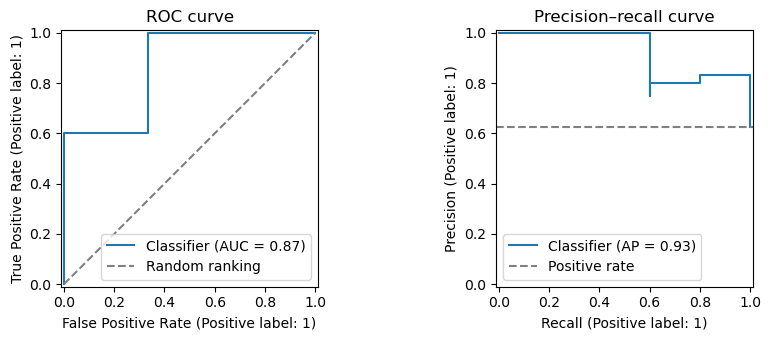

In [22]:
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    log_loss,
    roc_auc_score,
)

# The two columns give P(short wait) and P(long wait), in label order.
class_probabilities = np.column_stack([1 - long_wait_scores, long_wait_scores])
ranking_and_probability_metrics = {
    "ROC AUC": roc_auc_score(long_wait_labels, long_wait_scores),
    "Average precision": average_precision_score(long_wait_labels, long_wait_scores),
    "Log loss": log_loss(long_wait_labels, class_probabilities, labels=[0, 1]),
}
display(pd.Series(ranking_and_probability_metrics, name="Score").round(3))

# Read each curve from the original scores across many possible cutoffs.
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
RocCurveDisplay.from_predictions(long_wait_labels, long_wait_scores, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
axes[0].set_title("ROC curve")
axes[0].legend(loc="lower right")

PrecisionRecallDisplay.from_predictions(long_wait_labels, long_wait_scores, ax=axes[1])
axes[1].axhline(
    long_wait_labels.mean(), linestyle="--", color="gray", label="Positive rate"
)
axes[1].set_title("Precision–recall curve")
axes[1].legend(loc="lower left")
fig.tight_layout()
plt.show()

Maya can tolerate one false alert on these practice cases. Compare a few cutoffs on the **same** scores while keeping the actual labels fixed. Look at the number of alerts as well as the metric values. For a real system, choose the cutoff on representative validation data with the review budget in mind, then check it on the untouched test set.

In [23]:
threshold_results = []

for threshold in (0.70, 0.50, 0.35, 0.25):
    predicted = (long_wait_scores >= threshold).astype(int)
    _, false_alerts, missed_long_waits, _ = confusion_matrix(
        long_wait_labels, predicted, labels=[0, 1]
    ).ravel()

    # Track the operational workload and both types of error.
    threshold_results.append({
        "cutoff": threshold,
        "alerts": int(predicted.sum()),
        "false_alerts": false_alerts,
        "missed_long_waits": missed_long_waits,
        "precision": precision_score(long_wait_labels, predicted, zero_division=0),
        "recall": recall_score(long_wait_labels, predicted, zero_division=0),
    })

display(pd.DataFrame(threshold_results).round(2))

,cutoff,alerts,false_alerts,missed_long_waits,precision,recall
0,0.70,3,0,2,1.00,0.6
1,0.50,4,1,2,0.75,0.6
2,0.35,6,1,0,0.83,1.0
3,0.25,7,2,0,0.71,1.0


At 0.35 the example catches all five long waits with one false alert. At 0.25 it still catches the five, and one more short-wait ticket reaches the review queue. The ranking metrics on these scores are unchanged because the scores themselves stayed fixed.

**Where do scores come from in a real model?** For a binary scikit-learn classifier such as `LogisticRegression`, fit on training examples and call `predict_proba(X_val)` on validation features. The columns are ordered by `model.classes_`. Take the column for your defined positive label. This small worked example creates the training labels from past waits and uses the same queue-size feature.

In [24]:
from sklearn.linear_model import LogisticRegression

# Turn the recorded training waits into actual classes, then fit the classifier.
classifier = LogisticRegression()
classifier.fit(X_train, (y_train > 30).astype(int))

# Find the probability column for label 1 using the fitted class order.
positive_column = list(classifier.classes_).index(1)
validation_long_wait_scores = classifier.predict_proba(X_val)[:, positive_column]
validation_long_wait_labels = (y_val > 30).astype(int)

print(f"Queue classifier validation ROC AUC: "
      f"{roc_auc_score(validation_long_wait_labels, validation_long_wait_scores):.3f}")
display(X_val.assign(
    actual_long_wait=validation_long_wait_labels,
    score=validation_long_wait_scores.round(2),
).head())

Queue classifier validation ROC AUC: 0.914


,queue_size,actual_long_wait,score
103,0,0,0.00
21,9,1,0.03
29,11,0,0.07
51,4,0,0.00
43,8,0,0.02


### 5.4 Multiclass classification · Read the per-class report

For ticket routing there is one label per ticket, chosen here from billing, login and delivery. Scikit-learn's **classification report** treats each class as the positive class in turn and reports its precision, recall, F1 and **support** (how many actual examples belong to the class).

| Average | How it combines results | When to use it |
| --- | --- | --- |
| **Macro** | Calculate each class's score, then average the scores equally. | When missing rare classes matters as much as missing common classes. |
| **Weighted** | Average the class scores with more weight for classes with higher support. | When you want an aggregate that reflects the observed mix of tickets. |
| **Micro** | Pool the counts across classes first and compute the metric from those counts. | When each individual decision should contribute equally. For single-label multiclass with all classes included, micro F1 equals accuracy. |

A weighted average can look strong when the model serves the largest class well. Inspect the per-class rows before deciding where routing needs work.

In [25]:
from sklearn.metrics import classification_report

# Example predicted routes from a ticket classifier on ten unseen cases.
actual_teams = ["billing"] * 6 + ["login"] * 3 + ["delivery"]
predicted_teams = [
    "billing", "billing", "billing", "login", "billing", "billing",
    "login", "login", "billing", "billing",
]
team_order = ["billing", "login", "delivery"]

print(classification_report(
    actual_teams, predicted_teams, labels=team_order, zero_division=0
))
print(f"Micro F1: {f1_score(actual_teams, predicted_teams, average='micro'):.2f}")

              precision    recall  f1-score   support

     billing       0.71      0.83      0.77         6
       login       0.67      0.67      0.67         3
    delivery       0.00      0.00      0.00         1

    accuracy                           0.70        10
   macro avg       0.46      0.50      0.48        10
weighted avg       0.63      0.70      0.66        10

Micro F1: 0.70


**Check.** Which queue needs investigation even though accuracy is 70%? Delivery. Its only example was routed to billing, so delivery recall is zero. With one delivery example, collect more representative cases before estimating its real routing performance.

### 5.5 Regression · Measure how far away the estimate was

Let the **signed error** be `predicted − actual`. A negative error is an underestimate. Errors of −5 and +5 minutes average to zero, yet each prediction missed by 5. To measure error size, use absolute or squared errors. Keep the predictions at full precision for scoring and round only the displayed results.

| Metric | Calculation and units | When to use it |
| --- | --- | --- |
| **MAE · Mean Absolute Error** | Average absolute error, in minutes. Lower is better. | A clear everyday score for how far off the estimate is on average. |
| **Median Absolute Error** | Median of absolute errors, in minutes. Lower is better. | When you want the middle size of a miss and a few extremely large misses would dominate another metric. Check large misses separately. |
| **MSE · Mean Squared Error** | Average squared error, in minutes². Lower is better. | When large errors should weigh more or squared error is the training objective. |
| **RMSE · Root Mean Squared Error** | Square root of MSE, in minutes. Lower is better. | When large misses matter and you want the result in the target's original units. |
| **R² · Coefficient of Determination** | `1 − sum(squared errors) / sum((actual − mean(actual))²)`. Unitless. Higher is better. | To compare how much squared error remains relative to the mean of the evaluated targets. A perfect fit scores 1. A score of 0 matches that mean reference and a negative score is possible. R² is a poor diagnostic when the actual targets are constant. |
| **MAPE · Mean Absolute Percentage Error** | Average of `absolute error / absolute actual`, expressed as a percentage. Lower is better. | When relative error matters, such as demand forecasts with positive targets far from zero. Zero or tiny actuals can distort the result, so use another metric when they matter. |

For a fast hand calculation, take two predictions that missed by 2 and 10 minutes. MAE is 6 minutes, MSE is 52 minutes², and RMSE is about 7.21 minutes. Squaring makes the 10-minute miss contribute much more.

In [26]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    median_absolute_error,
    r2_score,
)

# Use the same validation tickets for both predictions.
training_mean_predictions = np.full(len(y_val), y_train.mean())
wait_predictions = {
    "Training mean baseline": training_mean_predictions,
    "Fitted wait model": validation_predictions,
}
regression_scores = []

for approach, predictions in wait_predictions.items():
    mse = mean_squared_error(y_val, predictions)
    regression_scores.append({
        "Approach": approach,
        "MAE (min)": mean_absolute_error(y_val, predictions),
        "Median AE (min)": median_absolute_error(y_val, predictions),
        "MSE (min²)": mse,
        "RMSE (min)": np.sqrt(mse),
        "R²": r2_score(y_val, predictions),
    })

display(pd.DataFrame(regression_scores).set_index("Approach").round(2))

# Use a separate example where positive actuals make percentage errors meaningful.
actual_orders = np.array([100, 200, 400])
predicted_orders = np.array([90, 220, 360])
mape = mean_absolute_percentage_error(actual_orders, predicted_orders)
print(f"Order demand example MAPE: {100 * mape:.1f}%")

,MAE (min),Median AE (min),MSE (min²),RMSE (min),R²
Approach,,,,,
Training mean baseline,11.04,8.90,166.28,12.89,-0.02
Fitted wait model,4.77,4.62,30.29,5.50,0.81


Order demand example MAPE: 10.0%


The fitted wait model has a validation MAE of **4.77 minutes**, compared with **11.04 minutes** for the training mean baseline. This is an average error size over 24 validation tickets. The R² metric uses the mean of the evaluated targets as its mathematical reference. The baseline in our table learns its prediction from **training** data, so its R² can differ from zero.

For the order example each prediction misses by 10% of actual demand. Scikit-learn returns MAPE as a fraction, so we multiply by 100 to display percent. Real tickets can be picked up immediately, so use MAE for a wait-time metric that works at zero.

### 5.6 Choose a metric for the decision

| Application | Start with | Read alongside it |
| --- | --- | --- |
| Catch as many long waits as possible | Recall | Precision and false-alert count so the team knows the workload. |
| Send only a few high-value alerts | Precision at an acceptable recall | Number of alerts and missed long waits. |
| Rank rare urgent cases before setting a cutoff | Average precision and the PR curve | Positive rate and the operating point you can support. |
| Use or communicate class probabilities | Log loss | A calibration check on a larger representative sample. |
| Route among several support teams | Per-class precision and recall, plus macro F1 | Support and which teams are confused. |
| Give customers wait estimates in minutes | MAE against a baseline | Direction of errors and the tickets with the biggest misses. |
| Give severe wait errors extra weight | RMSE | MAE and a review of large underestimates. |
| Compare relative forecast errors at different volumes | MAPE for positive actuals away from zero | An error in the original units and performance by volume. |

